# 04 · XGBoost, tuning, experiment tracking and explanations

**Continue from notebook 03.** We use the same saved 29 features; no feature creation or new split.
Our sequence: **initial XGBoost → Optuna tuning → comparison → local MLflow → local SHAP → save**.

Everything runs on your computer: CPU training, two SQLite databases, local model files and plots.
No cloud account, remote tracking server, GPU or paid service is required. The holdout remains closed.

**Before opening the notebook**, from the project terminal:
```bash
uv add "xgboost>=3.1,<4" "optuna>=4.5,<5" "mlflow>=3.5,<4" "shap>=0.49,<1"
```



In [1]:
import os
os.environ["MLFLOW_DISABLE_TELEMETRY"]="true"

import json
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import optuna
import mlflow
import mlflow.xgboost
import shap

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay)

from src.utils.paths import PROJECT_ROOT, PROCESSED_DIR, MODELS_DIR

SEED=42
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format","{:,.3f}".format)

/home/teehy/ml_class/churn-prediction-mle/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
train_df = pd.read_csv(PROCESSED_DIR / "features_train.csv")
eval_df = pd.read_csv(PROCESSED_DIR / "features_eval.csv")
feature_cols = json.loads((MODELS_DIR / "feature_columns.json").read_text())
baselines = pd.read_csv(PROCESSED_DIR / "baseline_results.csv", index_col=0).T

X_train, y_train = train_df[feature_cols], train_df["Churn"]
X_eval, y_eval = eval_df[feature_cols], eval_df["Churn"]
assert "Churn" not in feature_cols and "customerID" not in feature_cols
assert list(X_train.columns) == list(X_eval.columns)
assert X_train.isna().sum().sum() == 0 and X_eval.isna().sum().sum() == 0
print("train:", X_train.shape, "| eval:", X_eval.shape)
baselines

train: (4930, 29) | eval: (1056, 29)


,accuracy,precision,recall,f1,roc_auc
dummy,0.735,0.000,0.000,0.000,0.500
logistic_regression,0.806,0.657,0.561,0.605,0.845
decision_tree,0.789,0.636,0.475,0.544,0.833


In [5]:
baselines.T

,dummy,logistic_regression,decision_tree
accuracy,0.735,0.806,0.789
precision,0.000,0.657,0.636
recall,0.000,0.561,0.475
f1,0.000,0.605,0.544
roc_auc,0.500,0.845,0.833


## 3. Train an initial XGBoost model
Gradient boosting builds trees sequentially. Each new tree follows information from the loss gradients
to improve the ensemble's current predictions. Its contribution is reduced by the learning rate.

| Setting | Meaning |
|---|---|
| `binary:logistic` | Binary classification with churn probability output |
| `logloss` | Probability loss recorded by XGBoost; not the metric Optuna optimises |
| `n_estimators` | Number of boosting rounds |
| `learning_rate` | Contribution of each added tree |
| `max_depth` | Maximum depth of each tree |
| `hist` | Efficient histogram-based tree construction |
| `n_jobs=2` | Limit CPU use to two threads per fit |

No scaler is needed. We start with explicit settings rather than searching immediately.

In [3]:
common_params = {"objective": "binary:logistic", "eval_metric": "logloss",
                 "tree_method": "hist", "device": "cpu", "random_state": SEED, "n_jobs": 2}


initial_params = {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 3,
                  "subsample": 1.0, "colsample_bytree": 1.0, "min_child_weight": 1}

initial = xgb.XGBClassifier(**common_params, **initial_params)
initial.fit(X_train, y_train)


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,1.0
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cpu'
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [ ]:
def evaluate(model):
    prediction = model.predict(X_eval)
    probability = model.predict_proba(X_eval)[:, 1
                                              ]
    return {"accuracy": accuracy_score(y_eval, prediction),
            "precision": precision_score(y_eval, prediction, zero_division=0),
            "recall": recall_score(y_eval, prediction),
            "f1": f1_score(y_eval, prediction),
            "roc_auc": roc_auc_score(y_eval, probability)}

initial_results = evaluate(initial)
pd.concat([baselines, pd.DataFrame([initial_results], index=["xgboost_initial"])])

,accuracy,precision,recall,f1,roc_auc
dummy,0.735,0.000,0.000,0.000,0.500
logistic_regression,0.806,0.657,0.561,0.605,0.845
decision_tree,0.789,0.636,0.475,0.544,0.833
xgboost_initial,0.799,0.647,0.536,0.586,0.849


## 5. Fix our cross-validation procedure before tuning
Use five stratified folds of **training data only**. The evaluation set does not enter Optuna's objective.
First obtain the initial XGBoost CV score with these same folds, so the tuning comparison is consistent.

As in Week 3, these scores are conditional on the feature representation saved by notebook 02.
The encoder and feature choices were established on the full training partition. This is a model
comparison on fixed features, not an unbiased evaluation of the full feature-discovery process.
End-to-end CV later must fit learned preprocessing inside each training fold.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
initial_cv = cross_val_score(initial, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
print(f"Initial CV AUC: {initial_cv.mean():.4f} ± {initial_cv.std(ddof=1):.4f}")

Initial CV AUC: 0.8442 ± 0.0132


## 6. Describe the search space
One Optuna **trial** proposes one configuration, fits five models through cross-validation,
and returns their mean ROC-AUC. TPE uses completed trials to guide later suggestions.

`suggest_int` chooses integer settings. `suggest_float(..., log=True)` searches learning rates on a log scale.
`subsample` selects a fraction of training rows for each boosting round; `colsample_bytree` selects a fraction
of columns per tree. `min_child_weight` is a minimum sum of second-order loss weights in a child,
not a literal minimum number of customers. Larger values can discourage overly specific splits.

No SMOTE, class-weight change, early stopping or pruning is added in this lesson. Keeping the procedure
fixed makes it easier to see what the hyperparameter search changes. `n_estimators` is tuned directly.

In [7]:
def objective(trial):

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
    }
    model = xgb.XGBClassifier(**common_params, **params)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    trial.set_user_attr("cv_std", float(scores.std(ddof=1)))
    
    return float(scores.mean())

In [9]:
WEEK4_DIR = MODELS_DIR / "week4"
WEEK4_DIR.mkdir(parents=True, exist_ok=True)
N_TRIALS = 100 # for you , increase this to 100
STUDY_NAME = "week4_xgboost_seed42_v1"
optuna.logging.set_verbosity(optuna.logging.WARNING)

study = optuna.create_study(
    study_name=STUDY_NAME,
    storage="sqlite:///" + (WEEK4_DIR / "optuna.db").as_posix(),
    direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
    load_if_exists=True,
)
remaining = max(0, N_TRIALS - len(study.trials))
if remaining:
    study.optimize(objective, n_trials=remaining, n_jobs=1)
print("Completed trials:", len(study.get_trials(states=[optuna.trial.TrialState.COMPLETE])))
print(f"Best training CV AUC: {study.best_value:.4f}")
study.best_params

Completed trials: 100
Best training CV AUC: 0.8487


{'n_estimators': 500,
 'learning_rate': 0.017605621624623004,
 'max_depth': 2,
 'subsample': 0.6683922887399896,
 'colsample_bytree': 0.7325459029822387,
 'min_child_weight': 7}

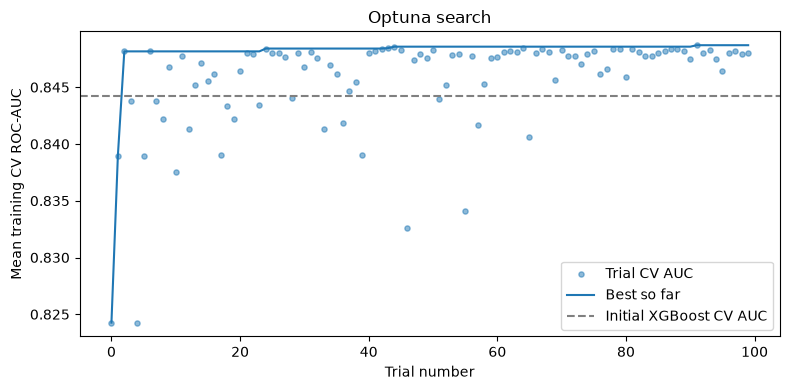

In [10]:
trials = study.trials_dataframe()
trials.to_csv(WEEK4_DIR / "optuna_trials.csv", index=False)
completed = trials[trials["state"] == "COMPLETE"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(completed["number"], completed["value"], s=14, alpha=0.5, label="Trial CV AUC")
ax.plot(completed["number"], completed["value"].cummax(), label="Best so far")
ax.axhline(initial_cv.mean(), linestyle="--", color="gray", label="Initial XGBoost CV AUC")
ax.set(xlabel="Trial number", ylabel="Mean training CV ROC-AUC", title="Optuna search")
ax.legend()
fig.tight_layout()
fig.savefig(WEEK4_DIR / "optuna_search.png")
plt.show()

In [11]:
tuned = xgb.XGBClassifier(**common_params, **study.best_params)
tuned.fit(X_train, y_train)
tuned_results = evaluate(tuned)
comparison = pd.concat([
    baselines,
    pd.DataFrame([initial_results, tuned_results], index=["xgboost_initial", "xgboost_tuned"]),
])
comparison

,accuracy,precision,recall,f1,roc_auc
dummy,0.735,0.000,0.000,0.000,0.500
logistic_regression,0.806,0.657,0.561,0.605,0.845
decision_tree,0.789,0.636,0.475,0.544,0.833
xgboost_initial,0.799,0.647,0.536,0.586,0.849
xgboost_tuned,0.800,0.648,0.539,0.589,0.852


### Check the fit gap and choose an XGBoost candidate using CV
A large training-to-evaluation gap can indicate overfitting. Do not choose settings by repeatedly
chasing evaluation scores. Our candidate choice below uses training CV AUC, not evaluation AUC.
Calling it an XGBoost candidate does not mean it has beaten every Week 3 model.


In [12]:
cv_means = {"xgboost_initial": float(initial_cv.mean()), "xgboost_tuned": study.best_value}
xgb_models = {"xgboost_initial": initial, "xgboost_tuned": tuned}
rows = []
for name, model in xgb_models.items():
    rows.append({"model": name, "cv_auc": cv_means[name],
                 "train_auc": roc_auc_score(y_train, model.predict_proba(X_train)[:, 1]),
                 "eval_auc": comparison.loc[name, "roc_auc"]})
candidate_name = max(cv_means, key=cv_means.get)
candidate = xgb_models[candidate_name]
print("CV-selected XGBoost candidate:", candidate_name)
pd.DataFrame(rows).set_index("model")

CV-selected XGBoost candidate: xgboost_tuned


,cv_auc,train_auc,eval_auc
model,,,
xgboost_initial,0.844,0.874,0.849
xgboost_tuned,0.849,0.861,0.852


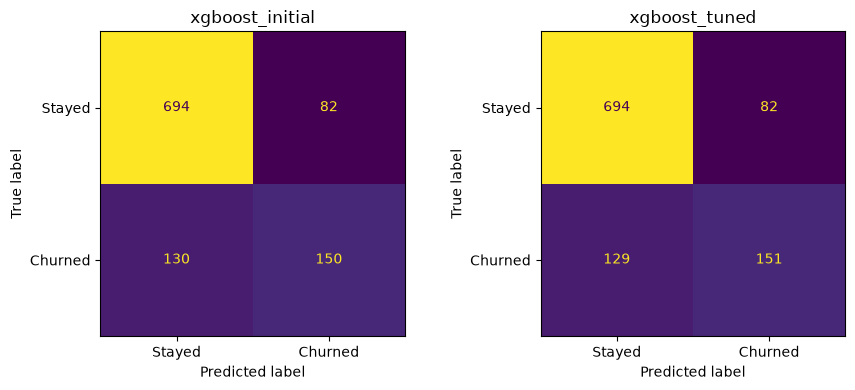

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, model) in zip(axes, xgb_models.items()):
    ConfusionMatrixDisplay.from_predictions(y_eval, model.predict(X_eval),
        display_labels=["Stayed", "Churned"], ax=ax, colorbar=False)
    ax.set_title(name)
fig.tight_layout()
fig.savefig(WEEK4_DIR / "xgboost_confusion_matrices.png")
plt.show()

In [14]:
TRACKING_DIR = PROJECT_ROOT / "mlruns"
TRACKING_DIR.mkdir(exist_ok=True)
TRACKING_URI = "sqlite:///" + (TRACKING_DIR / "mlflow.db").as_posix()
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_registry_uri(TRACKING_URI)
experiment_name = "churn-week4-local"
if mlflow.get_experiment_by_name(experiment_name) is None:
    mlflow.create_experiment(experiment_name, artifact_location=(TRACKING_DIR / "artifacts").as_uri())
mlflow.set_experiment(experiment_name)
print("Local MLflow:", TRACKING_URI)

2026/10/30 04:36:24 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/30 04:36:24 INFO mlflow.store.db.utils: Updating database tables


Local MLflow: sqlite:////home/teehy/ml_class/churn-prediction-mle/mlruns/mlflow.db


In [15]:
versions = {package: version(package) for package in ["xgboost", "optuna", "mlflow", "shap", "scikit-learn", "pandas", "numpy"]}
model_requirements = [f"{p}=={versions[p]}" for p in ["xgboost", "scikit-learn", "pandas", "numpy"]]
run_ids, model_uris = {}, {}
for name, model in xgb_models.items():
    params = initial_params if name == "xgboost_initial" else study.best_params
    with mlflow.start_run(run_name=name) as run:
        mlflow.log_params({**common_params, **params})
        mlflow.log_metrics({"cv_roc_auc": cv_means[name], **{f"eval_{k}": v for k, v in evaluate(model).items()}})
        mlflow.set_tags({"week": "4", "data_role": "development", "holdout_used": "false"})
        mlflow.log_dict(versions, "package_versions.json")
        info = mlflow.xgboost.log_model(model, name="model", model_format="json",
            input_example=X_train.head(3), pip_requirements=model_requirements)
        run_ids[name] = run.info.run_id
        model_uris[name] = info.model_uri
print("Two local runs logged.")

/home/teehy/ml_class/churn-prediction-mle/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
/home/teehy/ml_class/churn-prediction-mle/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent m

Two local runs logged.


In [16]:
print(f'uv run mlflow ui --backend-store-uri "{TRACKING_URI}" --host 127.0.0.1 --port 5000')

uv run mlflow ui --backend-store-uri "sqlite:////home/teehy/ml_class/churn-prediction-mle/mlruns/mlflow.db" --host 127.0.0.1 --port 5000
